In this lesson, you will discover a specific way to build models with ARIMA: AutoRegressive Integrated Moving Average. ARIMA models are particularly suited to fit data that shows non-stationarity.

## General concepts
To be able to work with ARIMA, there are some concepts you need to know about:

* 🎓 Stationarity. From a statistical context, stationarity refers to data whose distribution does not change when shifted in time. Non-stationary data, then, shows fluctuations due to trends that must be transformed to be analyzed. Seasonality, for example, can introduce fluctuations in data and can be eliminated by a process of 'seasonal-differencing'.

* 🎓 Differencing. Differencing data, again from a statistical context, refers to the process of transforming non-stationary data to make it stationary by removing its non-constant trend. "Differencing removes the changes in the level of a time series, eliminating trend and seasonality and consequently stabilizing the mean of the time series."

ARIMA in the context of time series
Let's unpack the parts of ARIMA to better understand how it helps us model time series and help us make predictions against it.

* AR - for AutoRegressive. Autoregressive models, as the name implies, look 'back' in time to analyze previous values in your data and make assumptions about them. These previous values are called 'lags'. An example would be data that shows monthly sales of pencils. Each month's sales total would be considered an 'evolving variable' in the dataset. This model is built as the "evolving variable of interest is regressed on its own lagged (i.e., prior) values."

* I - for Integrated. As opposed to the similar 'ARMA' models, the 'I' in ARIMA refers to its integrated aspect. The data is 'integrated' when differencing steps are applied so as to eliminate non-stationarity.

* MA - for Moving Average. The moving-average aspect of this model refers to the output variable that is determined by observing the current and past values of lags.

Bottom line: ARIMA is used to make a model fit the special form of time series data as closely as possible.

In this notebook, we demonstrate how to:

- prepare time series data for training an ARIMA time series forecasting model
- implement a simple ARIMA model to forecast the next HORIZON steps ahead (time t+1 through t+HORIZON) in the time series
- evaluate the model

The task is to forecast future values of electricity load. In this example, we show how to forecast one time step ahead, using historical load data only.

In [9]:
import os
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import datetime as dt
import math

from pandas.plotting import autocorrelation_plot
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import MinMaxScaler
from utils import load_data, mape
from IPython.display import Image

%matplotlib inline
pd.options.display.float_format = '{:,.2f}'.format
np.set_printoptions(precision=2)
warnings.filterwarnings("ignore") # specify to ignore warning messages

In [10]:
energy = load_data('../Data')[['load']]
energy.head(10)

,load
2012-01-01 00:00:00,"2,698.00"
2012-01-01 01:00:00,"2,558.00"
2012-01-01 02:00:00,"2,444.00"
2012-01-01 03:00:00,"2,402.00"
2012-01-01 04:00:00,"2,403.00"
2012-01-01 05:00:00,"2,453.00"
2012-01-01 06:00:00,"2,560.00"
2012-01-01 07:00:00,"2,719.00"
2012-01-01 08:00:00,"2,916.00"
2012-01-01 09:00:00,"3,105.00"


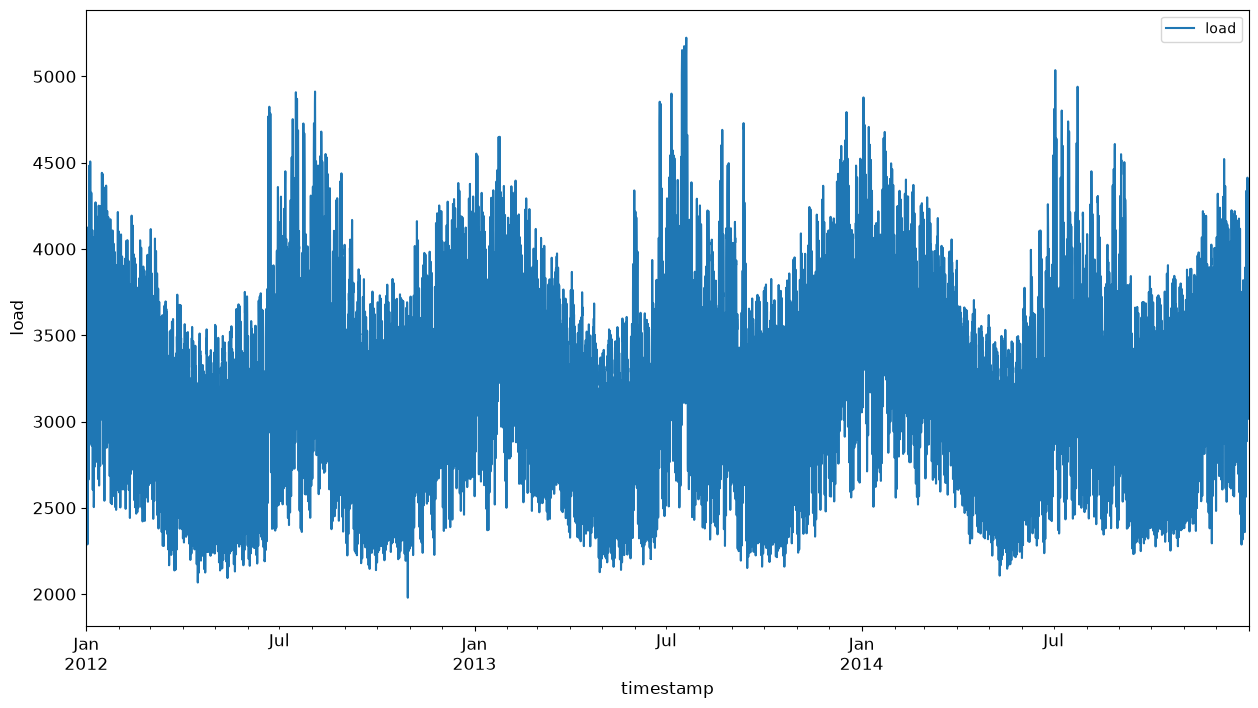

In [11]:
energy.plot(y='load', subplots=True, figsize=(15, 8), fontsize=12)
plt.xlabel('timestamp', fontsize=12)
plt.ylabel('load', fontsize=12)
plt.show()

## Create training and testing datasets
Now your data is loaded, so you can separate it into train and test sets. You'll train your model on the train set. As usual, after the model has finished training, you'll evaluate its accuracy using the test set. You need to ensure that the test set covers a later period in time from the training set to ensure that the model does not gain information from future time periods.

Allocate a two-month period from September 1 to October 31, 2014 to the training set. The test set will include the two-month period of November 1 to December 31, 2014:

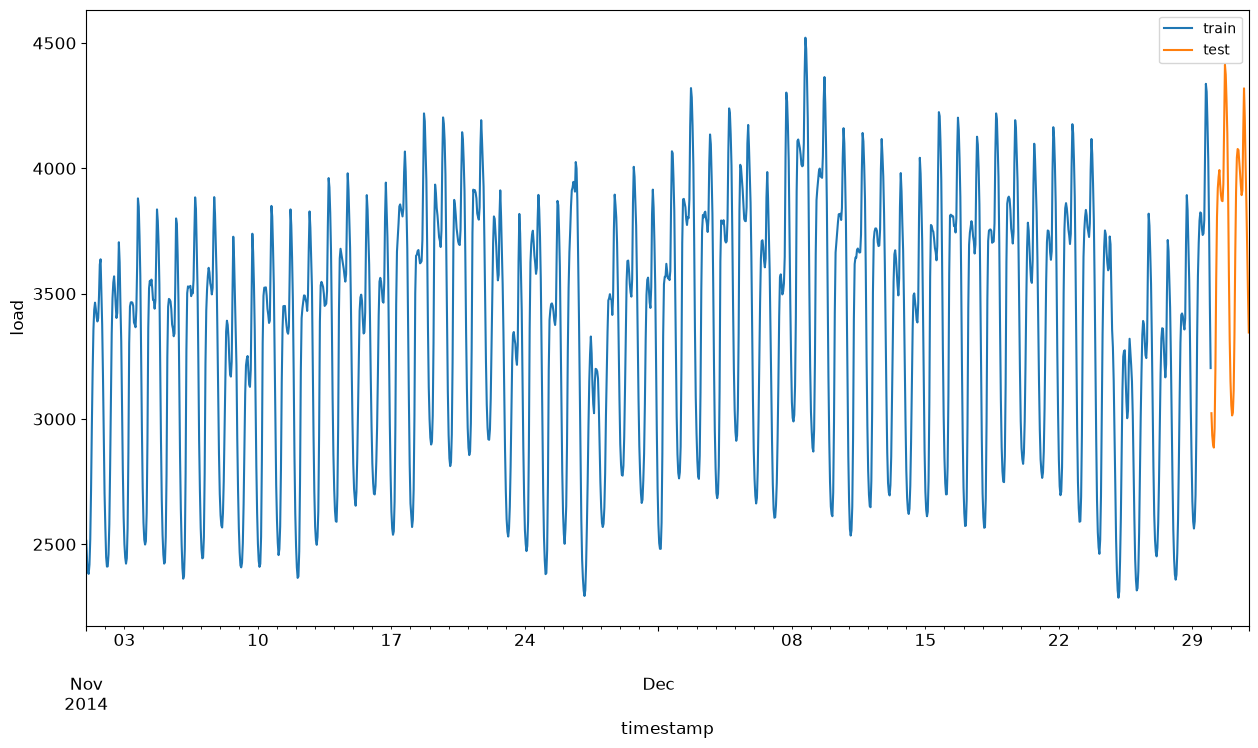

In [12]:
train_start_dt = '2014-11-01 00:00:00'
test_start_dt = '2014-12-30 00:00:00'

# Visualize the differences
energy[(energy.index < test_start_dt) & (energy.index >= train_start_dt)][['load']].rename(columns={'load':'train'}) \
    .join(energy[test_start_dt:][['load']].rename(columns={'load':'test'}), how='outer') \
    .plot(y=['train', 'test'], figsize=(15, 8), fontsize=12)
plt.xlabel('timestamp', fontsize=12)
plt.ylabel('load', fontsize=12)
plt.show()

# Prepare the data for training
Now, you need to prepare the data for training by performing filtering and scaling of your data. Filter your dataset to only include the time periods and columns you need, and scaling to ensure the data is projected in the interval 0,1.

Filter the original dataset to include only the aforementioned time periods per set and only including the needed column 'load' plus the date:

In [13]:
train = energy.copy()[(energy.index >= train_start_dt) & (energy.index < test_start_dt)][['load']]
test = energy.copy()[energy.index >= test_start_dt][['load']]

print('Training data shape: ', train.shape)
print('Test data shape: ', test.shape)

Training data shape:  (1416, 1)
Test data shape:  (48, 1)


In [14]:
# Scale the data to be in the range (0, 1).
scaler = MinMaxScaler()
train['load'] = scaler.fit_transform(train)
train.head(10)

,load
2014-11-01 00:00:00,0.10
2014-11-01 01:00:00,0.07
2014-11-01 02:00:00,0.05
2014-11-01 03:00:00,0.04
2014-11-01 04:00:00,0.06
2014-11-01 05:00:00,0.10
2014-11-01 06:00:00,0.19
2014-11-01 07:00:00,0.31
2014-11-01 08:00:00,0.40
2014-11-01 09:00:00,0.48


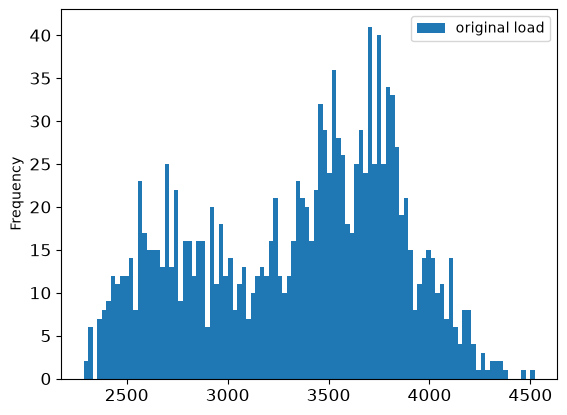

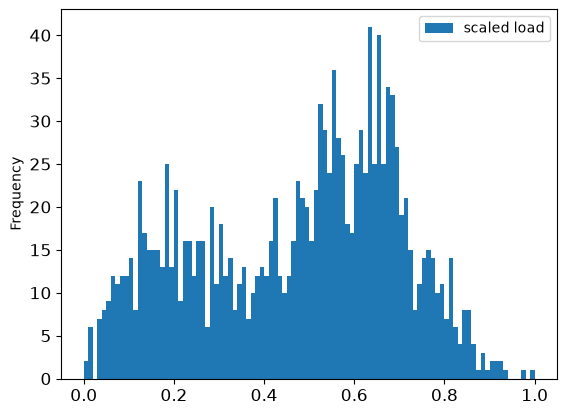

In [15]:
# Visualize arranged vs scaled data
energy[(energy.index >= train_start_dt) & (energy.index < test_start_dt)][['load']].rename(columns={'load':'original load'}).plot.hist(bins=100, fontsize=12)
train.rename(columns={'load':'scaled load'}).plot.hist(bins=100, fontsize=12)
plt.show()

In [16]:
# Now that you have calibrated the scaled data, you can scale the test data:
test['load'] = scaler.transform(test)
test.head()

,load
2014-12-30 00:00:00,0.33
2014-12-30 01:00:00,0.29
2014-12-30 02:00:00,0.27
2014-12-30 03:00:00,0.27
2014-12-30 04:00:00,0.30


## Implement ARIMA
It's time to implement ARIMA! You'll now use the statsmodels library that you installed earlier.

Now you need to follow several steps

1. Define the model by calling SARIMAX() and passing in the model parameters: p, d, and q parameters, and P, D, and Q parameters.

2. Prepare the model for the training data by calling the fit() function.

3. Make predictions calling the forecast() function and specifying the number of steps (the horizon) to forecast.

🎓 What are all these parameters for? In an ARIMA model there are 3 parameters that are used to help model the major aspects of a time series: seasonality, trend, and noise. These parameters are:

- p: the parameter associated with the auto-regressive aspect of the model, which incorporates past values. 

- d: the parameter associated with the integrated part of the model, which affects the amount of differencing (🎓 remember differencing 👆?) to apply to a time series. 

- q: the parameter associated with the moving-average part of the model.

Note: If your data has a seasonal aspect - which this one does - , we use a seasonal ARIMA model (SARIMA). In that case you need to use another set of parameters: P, D, and Q which describe the same associations as p, d, and q, but correspond to the seasonal components of the model.

In [17]:
# Start by setting your preferred horizon value. Let's try 3 hours:
# Specify the number of steps to forecast ahead
HORIZON = 3
print('Forecasting horizon:', HORIZON, 'hours')

Forecasting horizon: 3 hours


Selecting the best values for an ARIMA model's parameters can be challenging as it's somewhat subjective and time intensive. You might consider using an auto_arima() function from the pyramid library,

For now try some manual selections to find a good model:

In [18]:
order = (4, 1, 0)
seasonal_order = (1, 1, 0, 24)

model = SARIMAX(endog=train, order=order, seasonal_order=seasonal_order)
results = model.fit()

print(results.summary())

                                     SARIMAX Results                                      
Dep. Variable:                               load   No. Observations:                 1416
Model:             SARIMAX(4, 1, 0)x(1, 1, 0, 24)   Log Likelihood                3477.240
Date:                            Tue, 30 Jun 2026   AIC                          -6942.480
Time:                                    05:03:59   BIC                          -6911.053
Sample:                                11-01-2014   HQIC                         -6930.728
                                     - 12-29-2014                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.8400      0.016     52.182      0.000       0.808       0.872
ar.L2         -0.5219      0.034   

## Evaluate your model
To evaluate your model, you can perform the so-called walk forward validation. In practice, time series models are re-trained each time a new data becomes available. This allows the model to make the best forecast at each time step.

Starting at the beginning of the time series using this technique, train the model on the train data set. Then make a prediction on the next time step. The prediction is evaluated against the known value. The training set is then expanded to include the known value and the process is repeated.

Note: You should keep the training set window fixed for more efficient training so that every time you add a new observation to the training set, you remove the observation from the beginning of the set.

This process provides a more robust estimation of how the model will perform in practice. However, it comes at the computation cost of creating so many models. This is acceptable if the data is small or if the model is simple, but could be an issue at scale.

Walk-forward validation is the gold standard of time series model evaluation and is recommended for your own projects.

In [20]:
#First, create a test data point for each HORIZON step.
test_shifted = test.copy()

for t in range(1, HORIZON+1):
    test_shifted['load+'+str(t)] = test_shifted['load'].shift(-t, freq='h')

test_shifted = test_shifted.dropna(how='any')
test_shifted.head(5)

,load,load+1,load+2,load+3
2014-12-30 00:00:00,0.33,0.29,0.27,0.27
2014-12-30 01:00:00,0.29,0.27,0.27,0.30
2014-12-30 02:00:00,0.27,0.27,0.30,0.41
2014-12-30 03:00:00,0.27,0.30,0.41,0.57
2014-12-30 04:00:00,0.30,0.41,0.57,0.68


In [26]:
#Make predictions on your test data using this sliding window approach in a loop the size of the test data length:

training_window = 720 # dedicate 30 days (720 hours) for training

train_ts = train['load']
test_ts = test_shifted

history = [x for x in train_ts]
history = history[(-training_window):]

predictions = list()

order = (2, 1, 0)
seasonal_order = (1, 1, 0, 24)

for t in range(test_ts.shape[0]):
    model = SARIMAX(endog=history, order=order, seasonal_order=seasonal_order)
    model_fit = model.fit()
    yhat = model_fit.forecast(steps = HORIZON)
    predictions.append(yhat)
    obs = list(test_ts.iloc[t])
    # move the training window
    history.append(obs[0])
    history.pop(0)
    print(test_ts.index[t])
    print(t+1, ': predicted =', yhat, 'expected =', obs)

2014-12-30 00:00:00
1 : predicted = [0.32 0.29 0.28] expected = [0.32945389435989236, 0.2900626678603402, 0.2739480752014323, 0.26812891674127126]
2014-12-30 01:00:00
2 : predicted = [0.3  0.29 0.3 ] expected = [0.2900626678603402, 0.2739480752014323, 0.26812891674127126, 0.3025962399283795]
2014-12-30 02:00:00
3 : predicted = [0.27 0.28 0.32] expected = [0.2739480752014323, 0.26812891674127126, 0.3025962399283795, 0.40823634735899716]
2014-12-30 03:00:00
4 : predicted = [0.28 0.32 0.42] expected = [0.26812891674127126, 0.3025962399283795, 0.40823634735899716, 0.5689346463742166]
2014-12-30 04:00:00
5 : predicted = [0.3  0.39 0.54] expected = [0.3025962399283795, 0.40823634735899716, 0.5689346463742166, 0.6799462846911368]
2014-12-30 05:00:00
6 : predicted = [0.4  0.55 0.67] expected = [0.40823634735899716, 0.5689346463742166, 0.6799462846911368, 0.7309758281110115]
2014-12-30 06:00:00
7 : predicted = [0.57 0.68 0.75] expected = [0.5689346463742166, 0.6799462846911368, 0.73097582811101

In [30]:
#Compare the predictions to the actual load:
eval_df = pd.DataFrame(
    predictions,
    columns=['t+' + str(t) for t in range(1, HORIZON+1)]
)

eval_df['timestamp'] = test_shifted.index

eval_df = pd.melt(
    eval_df,
    id_vars='timestamp',
    value_name='prediction',
    var_name='h'
)

eval_df['actual'] = (
    test_shifted[[f'load+{t}' for t in range(1,HORIZON+1)]]
    .values
    .flatten()
)

eval_df[['prediction','actual']] = scaler.inverse_transform(
    eval_df[['prediction','actual']]
)

eval_df.head()

,timestamp,h,prediction,actual
0,2014-12-30 00:00:00,t+1,"3,008.68","2,935.00"
1,2014-12-30 01:00:00,t+1,"2,955.59","2,899.00"
2,2014-12-30 02:00:00,t+1,"2,900.08","2,886.00"
3,2014-12-30 03:00:00,t+1,"2,917.68","2,899.00"
4,2014-12-30 04:00:00,t+1,"2,947.54","2,886.00"


## Check model accuracy
Check the accuracy of your model by testing its mean absolute percentage error (MAPE) over all the predictions.

In [31]:
# express equation in code
if(HORIZON > 1):
    eval_df['APE'] = (eval_df['prediction'] - eval_df['actual']).abs() / eval_df['actual']
    print(eval_df.groupby('h')['APE'].mean())

h
t+1   0.11
t+2   0.16
t+3   0.11
Name: APE, dtype: float64


In [32]:
print('One step forecast MAPE: ', (mape(eval_df[eval_df['h'] == 't+1']['prediction'], eval_df[eval_df['h'] == 't+1']['actual']))*100, '%')

One step forecast MAPE:  10.596535834740783 %


In [33]:
print('Multi-step forecast MAPE: ', mape(eval_df['prediction'], eval_df['actual'])*100, '%')

Multi-step forecast MAPE:  12.44596919149002 %


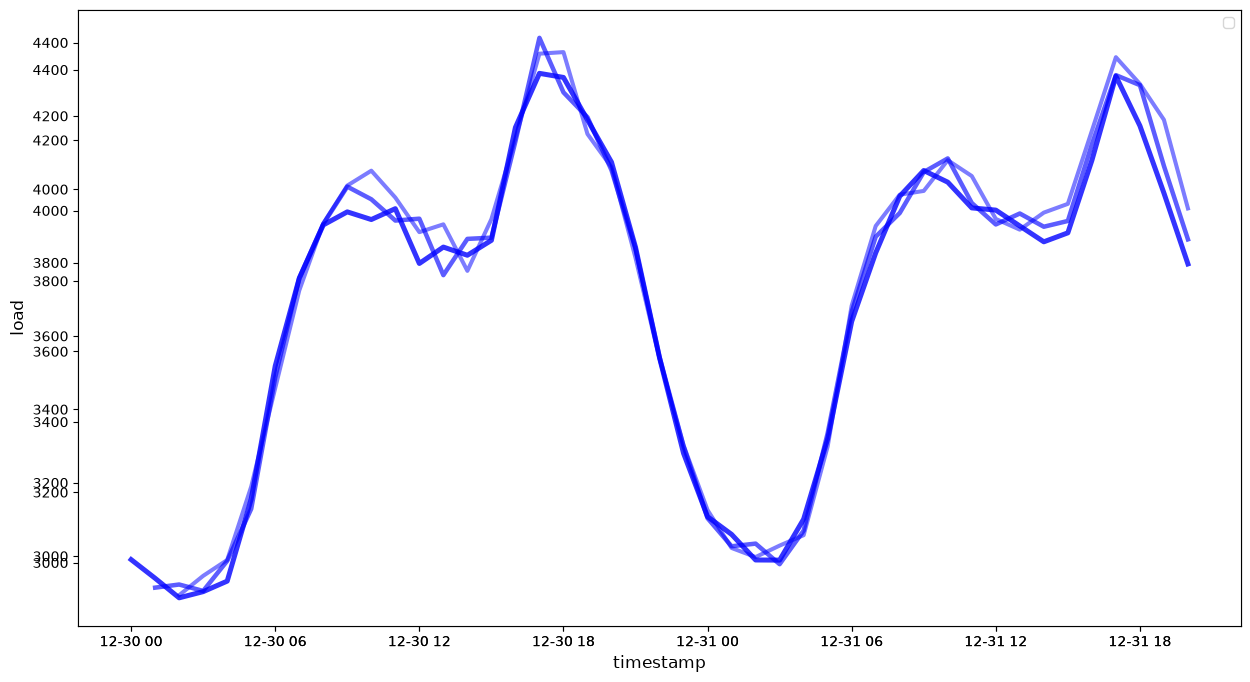

In [34]:
if(HORIZON == 1):
    ## Plotting single step forecast
    eval_df.plot(x='timestamp', y=['actual', 'prediction'], style=['r', 'b'], figsize=(15, 8))

else:
    ## Plotting multi step forecast
    plot_df = eval_df[(eval_df.h=='t+1')][['timestamp', 'actual']]
    for t in range(1, HORIZON+1):
        plot_df['t+'+str(t)] = eval_df[(eval_df.h=='t+'+str(t))]['prediction'].values

    fig = plt.figure(figsize=(15, 8))
    ax = plt.plot(plot_df['timestamp'], plot_df['actual'], color='red', linewidth=4.0)
    ax = fig.add_subplot(111)
    for t in range(1, HORIZON+1):
        x = plot_df['timestamp'][(t-1):]
        y = plot_df['t+'+str(t)][0:len(x)]
        ax.plot(x, y, color='blue', linewidth=4*math.pow(.9,t), alpha=math.pow(0.8,t))

    ax.legend(loc='best')

plt.xlabel('timestamp', fontsize=12)
plt.ylabel('load', fontsize=12)
plt.show()